# Diabetes progression

The first of two workflows on datasets called "diabetes". They share a name and almost nothing else: this one is a regression on 442 patients, and [Pima diabetes](../pima_diabetes.ipynb), the next one, a classification on 768 others, measured differently and stored differently. Both start the same way, by reading what the dataset is before writing a single step of the pipeline, because in both cases the data holds a surprise that a pipeline written blindly would get wrong.

## Reading the dataset first

Every dataset bundled with scikit-learn carries its documentation in `DESCR`:

In [ ]:
from sklearn.datasets import load_diabetes

diabetes = load_diabetes(as_frame=True)
print(diabetes.DESCR)

.. _diabetes_dataset:

Diabetes dataset
----------------

Ten baseline variables, age, sex, body mass index, average blood
pressure, and six blood serum measurements were obtained for each of n =
442 diabetes patients, as well as the response of interest, a
quantitative measure of disease progression one year after baseline.

**Data Set Characteristics:**

:Number of Instances: 442

:Number of Attributes: First 10 columns are numeric predictive values

:Target: Column 11 is a quantitative measure of disease progression one year after baseline

:Attribute Information:
    - age     age in years
    - sex
    - bmi     body mass index
    - bp      average blood pressure
    - s1      tc, total serum cholesterol
    - s2      ldl, low-density lipoproteins
    - s3      hdl, high-density lipoproteins
    - s4      tch, total cholesterol / HDL
    - s5      ltg, possibly log of serum triglycerides level
    - s6      glu, blood sugar level

Note: Each of these 10 feature variables have bee

Three facts from it decide the workflow:

- **What the target is:** "a quantitative measure of disease progression one year after baseline", for 442 patients who already have diabetes. It is not a diagnosis.
- **What the features are:** age, sex, body mass index (`bmi`), average blood pressure (`bp`), and six blood serum measurements (`s1` to `s6`), all taken at the start.
- **How they are stored:** the ten features "have been mean centered and scaled by the standard deviation times the square root of `n_samples`".

In [ ]:
diabetes.frame.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


That last fact is visible in the numbers: an age of 0.038, a sex of 0.05 or -0.045. Two consequences:

- The values can't be read in their units any more: no one is 0.038 years old, and sex, coded 1 or 2 in the source, has become two small decimals.
- The scaling was computed on all 442 patients, so any test set made from these rows was scaled with statistics that include it. For a scaling the effect is tiny, but it is the leak that [Data leakage](../../ml-fundamentals/data_leakage.ipynb) demonstrates, done before the data reached us.

`scaled=False` returns the original values, and the scaling can then be done inside the pipeline, on the training rows only, as in [California housing with pipelines](../california_with_pipelines.ipynb):

In [ ]:
raw = load_diabetes(as_frame=True, scaled=False)
X = raw.data
y = raw.target
raw.frame.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,59.0,2.0,32.1,101.0,157.0,93.2,38.0,4.0,4.8598,87.0,151.0
1,48.0,1.0,21.6,87.0,183.0,103.2,70.0,3.0,3.8918,69.0,75.0
2,72.0,2.0,30.5,93.0,156.0,93.6,41.0,4.0,4.6728,85.0,141.0
3,24.0,1.0,25.3,84.0,198.0,131.4,40.0,5.0,4.8903,89.0,206.0
4,50.0,1.0,23.0,101.0,192.0,125.4,52.0,4.0,4.2905,80.0,135.0


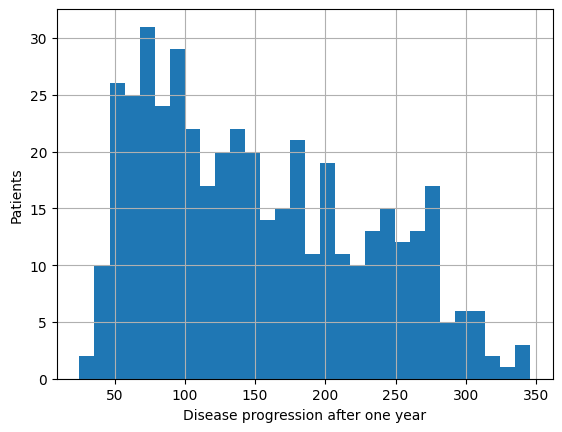

In [ ]:
import matplotlib.pyplot as plt

y.hist(bins=30)
plt.xlabel("Disease progression after one year")
plt.ylabel("Patients")
plt.show()

In [ ]:
y.describe().round(1)

count    442.0
mean     152.1
std       77.1
min       25.0
25%       87.0
50%      140.5
75%      211.5
max      346.0
Name: target, dtype: float64

Progression goes from 25 to 346, with a mean of about 152 and a standard deviation of about 77. The documentation gives no unit, only "a quantitative measure", so every error below is in that same unexplained unit. What can be judged is how an error compares with the spread of the target, and with a model that knows nothing.

## Comparing models

With only 442 patients, a validation set would be small and noisy, so the candidates are compared by 5-fold cross-validation on the training rows ([Cross-validation and hyperparameter search](../../ml-fundamentals/cross_validation_and_search.ipynb)), and the test set is used once at the end:

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
len(X_train), len(X_test)

(353, 89)

In [ ]:
import pandas as pd
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor

candidates = {
    "always the mean": DummyRegressor(),
    "linear regression": make_pipeline(StandardScaler(), LinearRegression()),
    "Ridge": make_pipeline(StandardScaler(), Ridge(alpha=10)),
    "k-nearest neighbours": make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=20)),
    "decision tree": DecisionTreeRegressor(max_depth=3, random_state=42),
    "random forest": RandomForestRegressor(min_samples_leaf=5, random_state=42, n_jobs=-1),
}
cross_validated_errors = pd.Series({
    name: -cross_val_score(model, X_train, y_train, cv=5, scoring="neg_mean_absolute_error").mean()
    for name, model in candidates.items()
}).sort_values().rename("cross-validated MAE")
cross_validated_errors.round(1)

Ridge                   45.4
linear regression       45.5
random forest           47.6
k-nearest neighbours    48.5
decision tree           52.0
always the mean         66.8
Name: cross-validated MAE, dtype: float64

Always predicting the training mean misses by about 67 on average; every real model does better, and the linear ones best, at about 45. Ridge and plain linear regression are practically tied (45.4 against 45.5): with 10 features and 353 patients, there is little overfitting for a penalty to correct. The forest and the neighbours, more flexible, don't beat them: 442 patients are few, and the relation seems close to a weighted sum. Ridge is chosen, by a hair.

In [ ]:
from sklearn.metrics import mean_absolute_error, r2_score

chosen_name = cross_validated_errors.idxmin()
final_model = candidates[chosen_name].fit(X_train, y_train)
y_predicted = final_model.predict(X_test)
{"test MAE": mean_absolute_error(y_test, y_predicted), "test R²": r2_score(y_test, y_predicted)}

{'test MAE': 42.85682524780061, 'test R²': 0.4572109567780849}

On the 89 test patients, Ridge misses by about 43 on average, and explains about 46% of the variance of the progression (its R²). More than half remains unexplained: ten measurements taken at the start say something about how the disease will evolve over a year, but far from everything. R² is not bounded below by 0 on new data, by the way: a model worse than predicting the mean has a negative one.

## What the model says

The weights of the linear model, on standardised features: the change in predicted progression when a feature rises by one standard deviation and the others stay the same:

In [ ]:
pd.Series(final_model[-1].coef_, index=X.columns).sort_values(key=abs, ascending=False).round(1)

bmi    25.6
s5     22.7
bp     16.3
s1    -12.9
sex   -11.0
s4      8.6
s3     -6.1
s6      2.9
age     1.9
s2      0.5
dtype: float64

Body mass index, `s5` (according to the documentation, "possibly" the log of the triglycerides) and blood pressure raise the predicted progression the most. Two weights need care:

- `s1` and `s2` (total cholesterol and LDL) rise and fall together (their correlation is 0.90). Plain least squares would split their shared effect into two large weights of opposite sign that largely cancel; Ridge's penalty pulls both towards 0 instead. Either way, neither weight means much alone, as in [California housing, step by step](../california_by_hand.ipynb).
- `sex` has a clear weight, but the documentation doesn't say which sex each code, 1 or 2, stands for. The weight can't be interpreted: one more thing that only reading the dataset reveals.

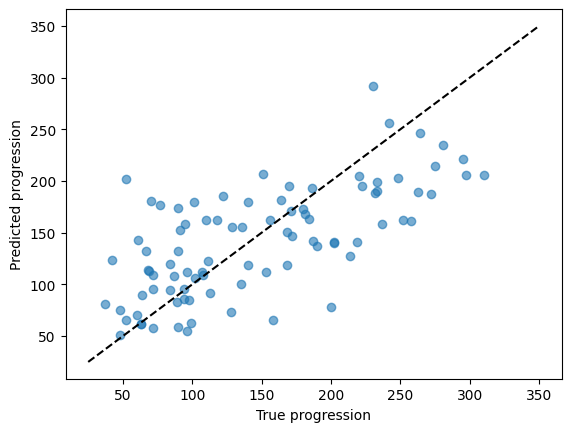

In [ ]:
plt.scatter(y_test, y_predicted, alpha=0.6)
plt.plot([25, 350], [25, 350], "k--")
plt.xlabel("True progression")
plt.ylabel("Predicted progression")
plt.show()

The predictions are squeezed towards the middle: patients with little progression are predicted too high, and those with the most are predicted too low, so the cloud is flatter than the dashed diagonal. That is what a model that explains less than half of the variance looks like: it knows the direction of the effects, but not enough to tell the extreme cases apart, and so pulls every prediction towards the average.